In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Environment is ready!")


Environment is ready!


In [2]:

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Training data:", train.shape)
print("Testing data:", test.shape)


Training data: (614, 13)
Testing data: (367, 12)


In [3]:

display(train.head())

train.info()

display(train.describe())


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [4]:

missing_values = pd.DataFrame({
    "Train": train.isnull().sum(),
    "Test": test.isnull().sum()
})

display(missing_values)


,Train,Test
ApplicantIncome,0,0.0
CoapplicantIncome,0,0.0
Credit_History,50,29.0
Dependents,15,10.0
Education,0,0.0
Gender,13,11.0
LoanAmount,22,5.0
Loan_Amount_Term,14,6.0
Loan_ID,0,0.0
Loan_Status,0,NaN


Loan_Status
Y    422
N    192
Name: count, dtype: int64
Loan_Status
Y    68.729642
N    31.270358
Name: proportion, dtype: float64


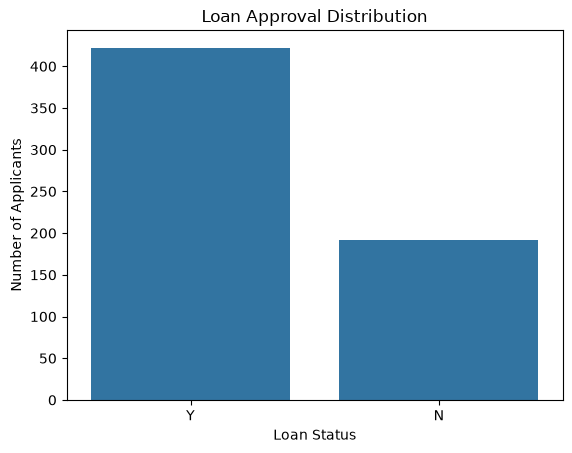

In [5]:

print(train["Loan_Status"].value_counts())

print(train["Loan_Status"].value_counts(normalize=True) * 100)

sns.countplot(data=train, x="Loan_Status")
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()


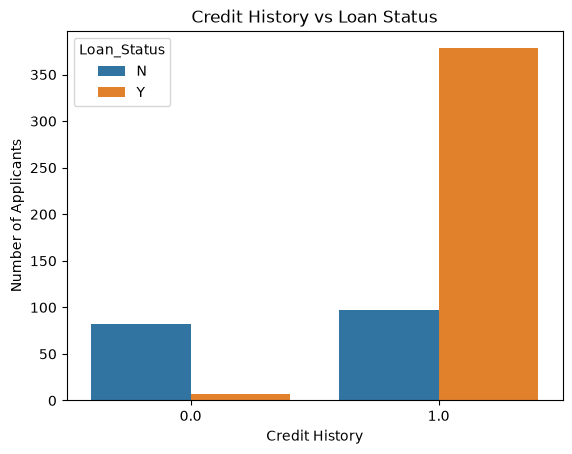

Loan_Status,N,Y
Credit_History,,
0.0,82,7
1.0,97,378


In [6]:

sns.countplot(
    data=train,
    x="Credit_History",
    hue="Loan_Status"
)

plt.title("Credit History vs Loan Status")
plt.xlabel("Credit History")
plt.ylabel("Number of Applicants")
plt.show()

display(pd.crosstab(
    train["Credit_History"],
    train["Loan_Status"]
))


In [7]:

X = train.drop(columns=["Loan_ID", "Loan_Status"])

y = train["Loan_Status"].map({"Y": 1, "N": 0})

X_test = test.drop(columns=["Loan_ID"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Test features shape:", X_test.shape)


Features shape: (614, 11)
Target shape: (614,)
Test features shape: (367, 11)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Validation samples:", X_val.shape)

Training samples: (491, 11)
Validation samples: (123, 11)


In [9]:
numerical_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [10]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline is ready!")

Preprocessing pipeline is ready!


In [11]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

tree_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [13]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_val)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8618,0.8400,0.9882,0.9081
1,Decision Tree,0.8211,0.8247,0.9412,0.8791
2,Random Forest,0.8211,0.8462,0.9059,0.8750


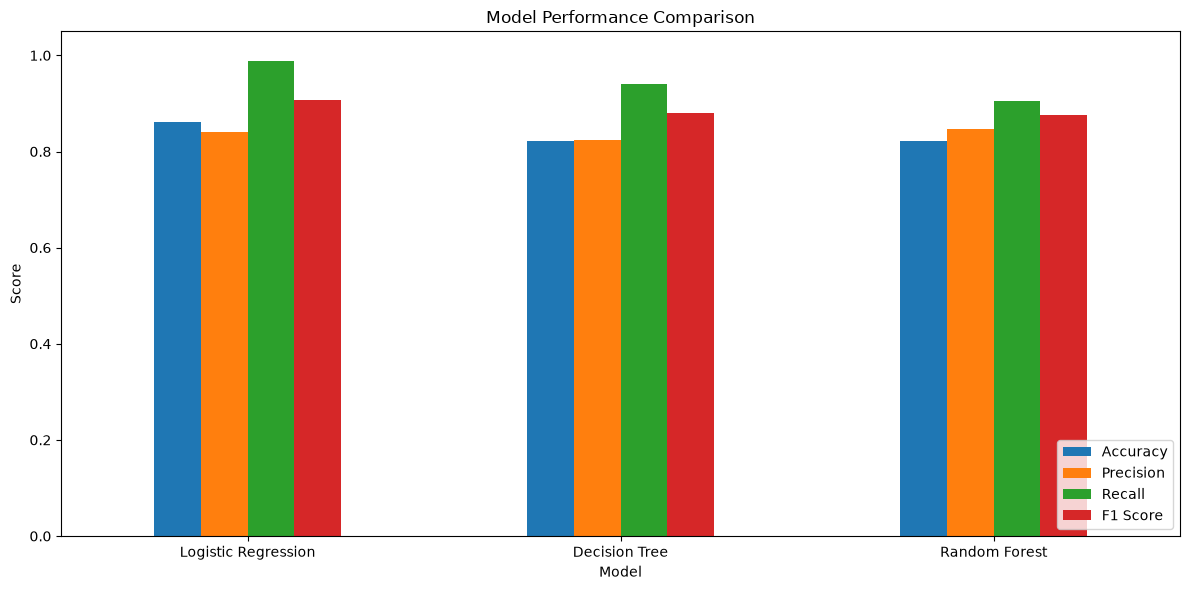

In [15]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Best Model: Logistic Regression
              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



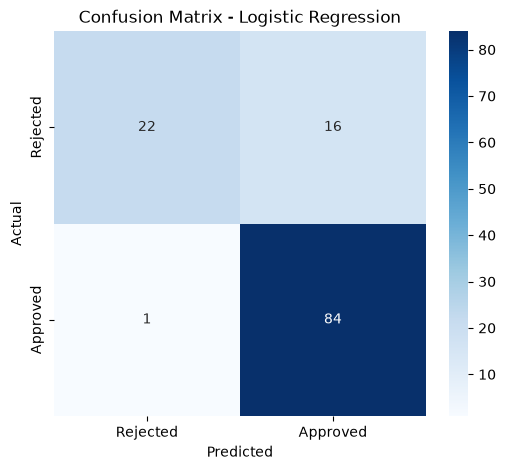

In [16]:
best_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

best_model = models[best_name]

best_predictions = best_model.predict(X_val)

print("Best Model:", best_name)

print(classification_report(
    y_val,
    best_predictions,
    target_names=["Rejected", "Approved"],
    zero_division=0
))

cm = confusion_matrix(y_val, best_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.title("Confusion Matrix - " + best_name)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [17]:
final_model = clone(best_model)

final_model.fit(X, y)

print("Selected Model:", best_name)
print("Final training completed!")
print("Training samples:", len(X))

Selected Model: Logistic Regression
Final training completed!
Training samples: 614


In [18]:
test_predictions = final_model.predict(X_test)

submission = pd.DataFrame({
    "Loan_ID": test["Loan_ID"],
    "Loan_Status": np.where(test_predictions == 1, "Y", "N")
})

display(submission.head(10))

print("Total predictions:", len(submission))
print(submission["Loan_Status"].value_counts())

,Loan_ID,Loan_Status
0,LP001015,Y
1,LP001022,Y
2,LP001031,Y
3,LP001035,Y
4,LP001051,Y
5,LP001054,Y
6,LP001055,Y
7,LP001056,N
8,LP001059,Y
9,LP001067,Y


Total predictions: 367
Loan_Status
Y    306
N     61
Name: count, dtype: int64


In [19]:
submission.to_csv("predictions.csv", index=False)

results_df.to_csv("evaluation_results.csv", index=False)

print("Predictions saved successfully!")
print("Evaluation results saved successfully!")

Predictions saved successfully!
Evaluation results saved successfully!
